In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import seaborn as sns
df=sns.load_dataset('diamonds')

In [3]:
df

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB


In [4]:
df.isnull().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

In [5]:
df


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


In [6]:
df.corr(numeric_only=True)

,carat,depth,table,price,x,y,z
carat,1.000000,0.028224,0.181618,0.921591,0.975094,0.951722,0.953387
depth,0.028224,1.000000,-0.295779,-0.010647,-0.025289,-0.029341,0.094924
table,0.181618,-0.295779,1.000000,0.127134,0.195344,0.183760,0.150929
price,0.921591,-0.010647,0.127134,1.000000,0.884435,0.865421,0.861249
x,0.975094,-0.025289,0.195344,0.884435,1.000000,0.974701,0.970772
y,0.951722,-0.029341,0.183760,0.865421,0.974701,1.000000,0.952006
z,0.953387,0.094924,0.150929,0.861249,0.970772,0.952006,1.000000


In [7]:
df['cut'].unique()

['Ideal', 'Premium', 'Good', 'Very Good', 'Fair']
Categories (5, object): ['Ideal', 'Premium', 'Very Good', 'Good', 'Fair']

In [8]:
df.describe()

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


<Axes: xlabel='x'>

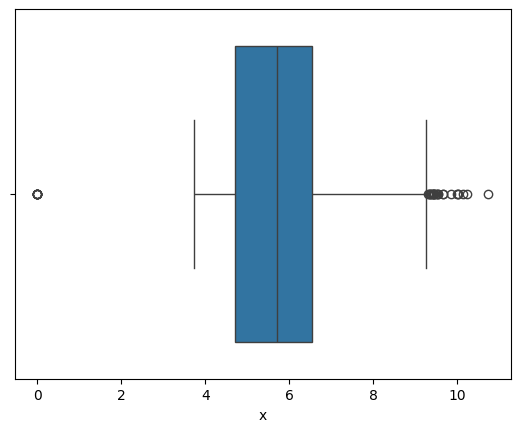

In [9]:
sns.boxplot(df,x='x')

<Axes: xlabel='y'>

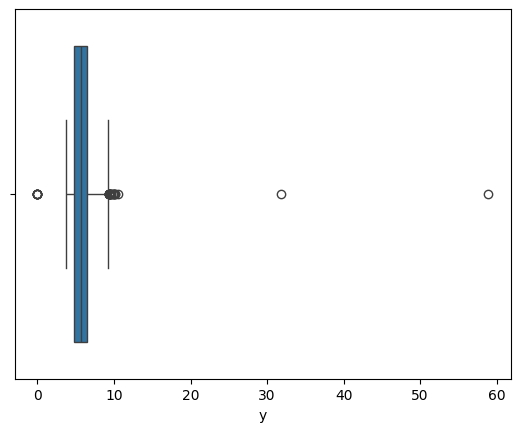

In [10]:
sns.boxplot(df,x='y')

<Axes: xlabel='z'>

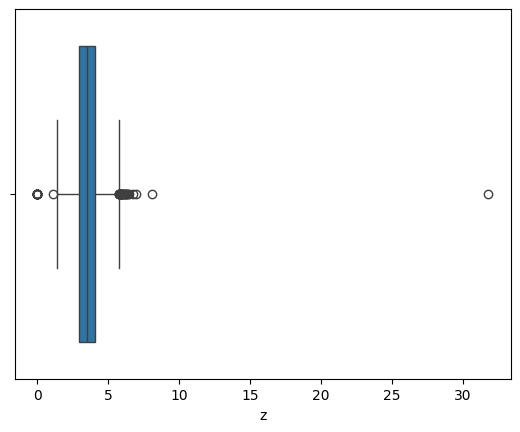

In [11]:
sns.boxplot(df,x='z')

In [12]:
print((df['x']==0).sum())
df.sort_values('x').tail()

8


,carat,cut,color,clarity,depth,table,price,x,y,z
26444,4.00,Very Good,I,I1,63.3,58.0,15984,10.01,9.94,6.31
25999,4.01,Premium,J,I1,62.5,62.0,15223,10.02,9.94,6.24
25998,4.01,Premium,I,I1,61.0,61.0,15223,10.14,10.10,6.17
27630,4.50,Fair,J,I1,65.8,58.0,18531,10.23,10.16,6.72
27415,5.01,Fair,J,I1,65.5,59.0,18018,10.74,10.54,6.98


In [13]:
print((df['y']==0).sum())
df.sort_values('y').tail()

7


,carat,cut,color,clarity,depth,table,price,x,y,z
25998,4.01,Premium,I,I1,61.0,61.0,15223,10.14,10.10,6.17
27630,4.50,Fair,J,I1,65.8,58.0,18531,10.23,10.16,6.72
27415,5.01,Fair,J,I1,65.5,59.0,18018,10.74,10.54,6.98
49189,0.51,Ideal,E,VS1,61.8,55.0,2075,5.15,31.80,5.12
24067,2.00,Premium,H,SI2,58.9,57.0,12210,8.09,58.90,8.06


In [14]:
print((df['z']==0).sum())
df.sort_values('z').tail()

20


,carat,cut,color,clarity,depth,table,price,x,y,z
27130,4.13,Fair,H,I1,64.8,61.0,17329,10.00,9.85,6.43
27630,4.50,Fair,J,I1,65.8,58.0,18531,10.23,10.16,6.72
27415,5.01,Fair,J,I1,65.5,59.0,18018,10.74,10.54,6.98
24067,2.00,Premium,H,SI2,58.9,57.0,12210,8.09,58.90,8.06
48410,0.51,Very Good,E,VS1,61.8,54.7,1970,5.12,5.15,31.80


In [15]:
df=df[(df['x']>0)& (df['x']<=10)&
(df['y']>0)& (df['y']<=10)&
(df['z']>0)& (df['z']<=10)]

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53912 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53912 non-null  float64 
 1   cut      53912 non-null  category
 2   color    53912 non-null  category
 3   clarity  53912 non-null  category
 4   depth    53912 non-null  float64 
 5   table    53912 non-null  float64 
 6   price    53912 non-null  int64   
 7   x        53912 non-null  float64 
 8   y        53912 non-null  float64 
 9   z        53912 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.4 MB


<Axes: xlabel='cut', ylabel='price'>

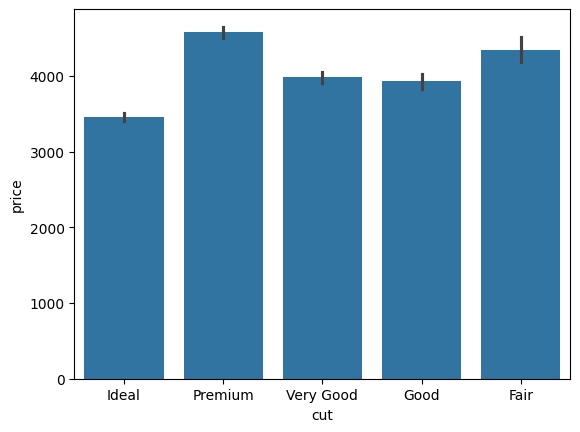

In [17]:
sns.barplot(df,x='cut',y='price')

<Axes: xlabel='price', ylabel='depth'>

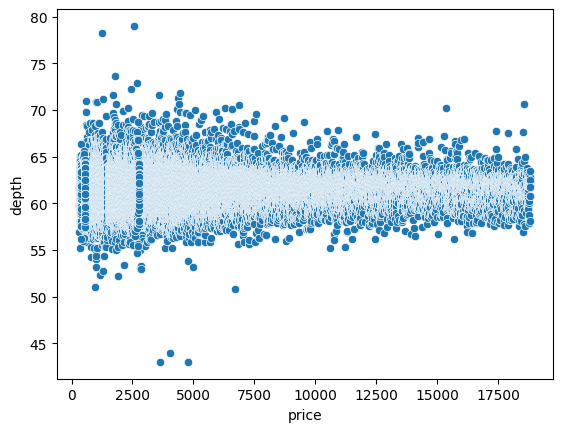

In [18]:
sns.scatterplot(df,x='price',y='depth')

In [19]:
print(((df['depth'] < 55) | (df['depth'] > 70)).sum())

45


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53912 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53912 non-null  float64 
 1   cut      53912 non-null  category
 2   color    53912 non-null  category
 3   clarity  53912 non-null  category
 4   depth    53912 non-null  float64 
 5   table    53912 non-null  float64 
 6   price    53912 non-null  int64   
 7   x        53912 non-null  float64 
 8   y        53912 non-null  float64 
 9   z        53912 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.4 MB


In [21]:
df=df[(df['depth']>55)& (df['depth']<70)]

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53864 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53864 non-null  float64 
 1   cut      53864 non-null  category
 2   color    53864 non-null  category
 3   clarity  53864 non-null  category
 4   depth    53864 non-null  float64 
 5   table    53864 non-null  float64 
 6   price    53864 non-null  int64   
 7   x        53864 non-null  float64 
 8   y        53864 non-null  float64 
 9   z        53864 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.4 MB


<Axes: xlabel='carat', ylabel='Count'>

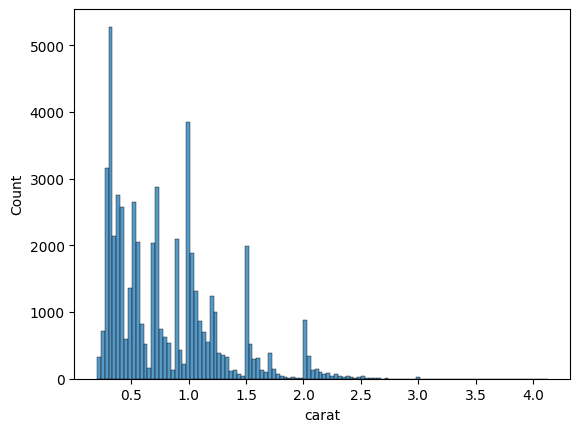

In [23]:
sns.histplot(df,x='carat')

<Axes: xlabel='price', ylabel='carat'>

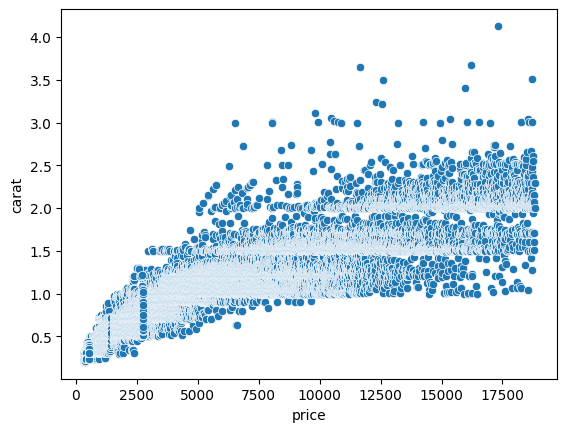

In [24]:
sns.scatterplot(df,x='price',y='carat')

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53864 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53864 non-null  float64 
 1   cut      53864 non-null  category
 2   color    53864 non-null  category
 3   clarity  53864 non-null  category
 4   depth    53864 non-null  float64 
 5   table    53864 non-null  float64 
 6   price    53864 non-null  int64   
 7   x        53864 non-null  float64 
 8   y        53864 non-null  float64 
 9   z        53864 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.4 MB


In [26]:
df=df[df['carat']<=3]

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53837 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53837 non-null  float64 
 1   cut      53837 non-null  category
 2   color    53837 non-null  category
 3   clarity  53837 non-null  category
 4   depth    53837 non-null  float64 
 5   table    53837 non-null  float64 
 6   price    53837 non-null  int64   
 7   x        53837 non-null  float64 
 8   y        53837 non-null  float64 
 9   z        53837 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.4 MB


<Axes: xlabel='price', ylabel='table'>

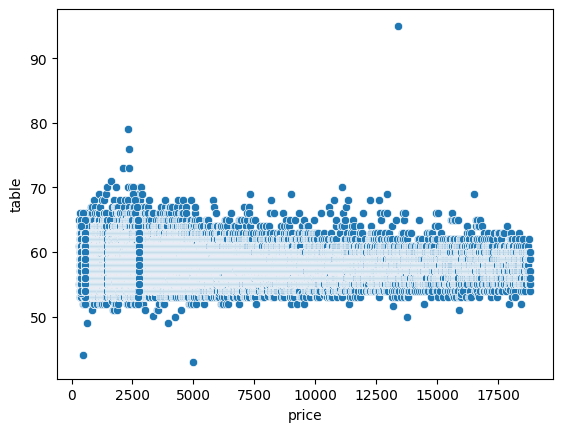

In [28]:
sns.scatterplot(df,x='price',y='table')

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53837 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53837 non-null  float64 
 1   cut      53837 non-null  category
 2   color    53837 non-null  category
 3   clarity  53837 non-null  category
 4   depth    53837 non-null  float64 
 5   table    53837 non-null  float64 
 6   price    53837 non-null  int64   
 7   x        53837 non-null  float64 
 8   y        53837 non-null  float64 
 9   z        53837 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.4 MB


In [30]:
df=df[(df['table']>50) & (df['table']<70)]

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53817 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53817 non-null  float64 
 1   cut      53817 non-null  category
 2   color    53817 non-null  category
 3   clarity  53817 non-null  category
 4   depth    53817 non-null  float64 
 5   table    53817 non-null  float64 
 6   price    53817 non-null  int64   
 7   x        53817 non-null  float64 
 8   y        53817 non-null  float64 
 9   z        53817 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.4 MB


In [32]:
df['cut'].unique()

['Ideal', 'Premium', 'Good', 'Very Good', 'Fair']
Categories (5, object): ['Ideal', 'Premium', 'Very Good', 'Good', 'Fair']

In [33]:
df['color'].unique()

['E', 'I', 'J', 'H', 'F', 'G', 'D']
Categories (7, object): ['D', 'E', 'F', 'G', 'H', 'I', 'J']

<Axes: xlabel='color', ylabel='price'>

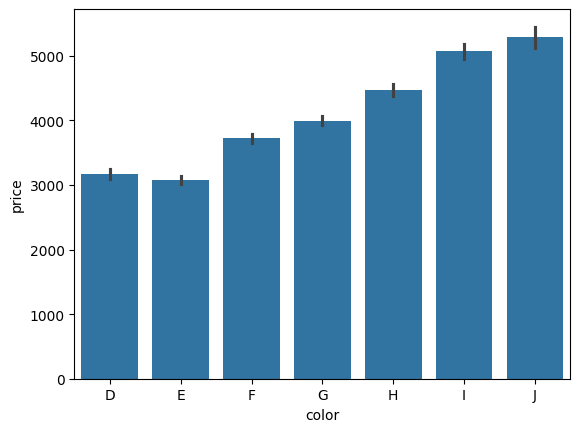

In [34]:
sns.barplot(df,x='color',y='price')

In [35]:
df['clarity'].unique()

['SI2', 'SI1', 'VS1', 'VS2', 'VVS2', 'VVS1', 'I1', 'IF']
Categories (8, object): ['IF', 'VVS1', 'VVS2', 'VS1', 'VS2', 'SI1', 'SI2', 'I1']

<Axes: xlabel='clarity', ylabel='price'>

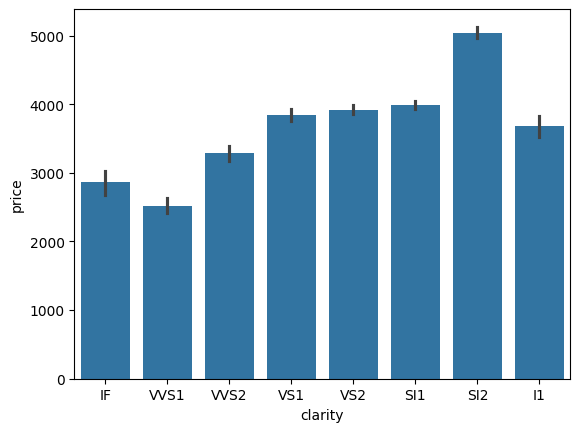

In [36]:
sns.barplot(df,x='clarity',y='price')


In [37]:
cut_map = {'Fair': 1, 'Good': 2, 'Very Good': 3, 'Premium': 4, 'Ideal': 5}
color_map = {'J': 1, 'I': 2, 'H': 3, 'G': 4, 'F': 5, 'E': 6, 'D': 7}
clarity_map = {'I1': 1, 'SI2': 2, 'SI1': 3, 'VS2': 4, 'VS1': 5, 'VVS2': 6, 'VVS1': 7, 'IF': 8}

df['cut'] = df['cut'].map(cut_map)
df['color'] = df['color'].map(color_map)
df['clarity'] = df['clarity'].map(clarity_map)

In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53817 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53817 non-null  float64 
 1   cut      53817 non-null  category
 2   color    53817 non-null  category
 3   clarity  53817 non-null  category
 4   depth    53817 non-null  float64 
 5   table    53817 non-null  float64 
 6   price    53817 non-null  int64   
 7   x        53817 non-null  float64 
 8   y        53817 non-null  float64 
 9   z        53817 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.4 MB


In [39]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score,KFold

In [40]:
x=df.drop(columns='price')
y=df['price']

In [41]:
model_linear=LinearRegression()
kf = KFold(n_splits=5, shuffle=True, random_state=42)
linear_cv=cross_val_score(model_linear,x,y,cv=kf)
linear_cv
linear_cv.mean()

np.float64(0.9135476310735433)

In [42]:
tree_model=RandomForestRegressor(n_estimators=100, random_state=42)
random_cv=cross_val_score(tree_model,x,y,cv=kf,n_jobs=-1)
random_cv.mean()

np.float64(0.9820005204984567)

In [43]:
from xgboost import XGBRegressor
xgb_model=XGBRegressor(n_estimators=100, random_state=42,learning_rate=.1)
xgb_cv=cross_val_score(xgb_model,x,y,cv=kf)
xgb_cv.mean()


np.float64(0.9828205347061157)